In [40]:
from sklearn.datasets import load_iris 
import pandas as pd
iris_dataset = load_iris()
print("Keys of iris dataset: ", iris_dataset.keys())
'''Data - measurements of different flowers
   Target - Species of flowers encoded numerically
   Target_Names - Names of the species 
   DESCR - Brief description of the database
   feature_names - petal length, petal width, sepal length, sepal width
   '''
#print(iris_dataset['DESCR'])
iris_dataset.target
iris_dataset.target_names

Keys of iris dataset:  dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [41]:
print(iris_dataset['data'].shape)

(150, 4)


In [42]:
print(iris_dataset['data'][:8]) #first five rows of the dataset

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]]


In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(iris_dataset['data'], iris_dataset['target'])
y_train

array([2, 2, 2, 2, 0, 2, 2, 1, 1, 0, 2, 1, 0, 0, 2, 0, 0, 2, 0, 1, 1, 2,
       2, 1, 1, 1, 1, 0, 0, 0, 0, 0, 2, 2, 1, 0, 0, 2, 1, 1, 2, 2, 0, 0,
       0, 1, 2, 0, 1, 0, 1, 0, 1, 2, 1, 1, 1, 0, 0, 2, 1, 1, 1, 1, 0, 2,
       2, 0, 2, 2, 1, 2, 1, 1, 0, 2, 0, 1, 1, 0, 1, 0, 2, 2, 0, 0, 0, 0,
       1, 1, 1, 1, 2, 0, 0, 2, 2, 1, 2, 2, 1, 1, 0, 0, 2, 2, 2, 1, 0, 0,
       2, 2])

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  6.3               2.8                5.1               1.5
1                  6.7               3.1                5.6               2.4
2                  7.7               3.8                6.7               2.2
3                  5.8               2.7                5.1               1.9
4                  4.7               3.2                1.6               0.2
..                 ...               ...                ...               ...
107                5.0               2.3                3.3               1.0
108                4.8               3.4                1.6               0.2
109                4.9               3.1                1.5               0.2
110                6.7               2.5                5.8               1.8
111                6.5               3.0                5.5               1.8

[112 rows x 4 columns]


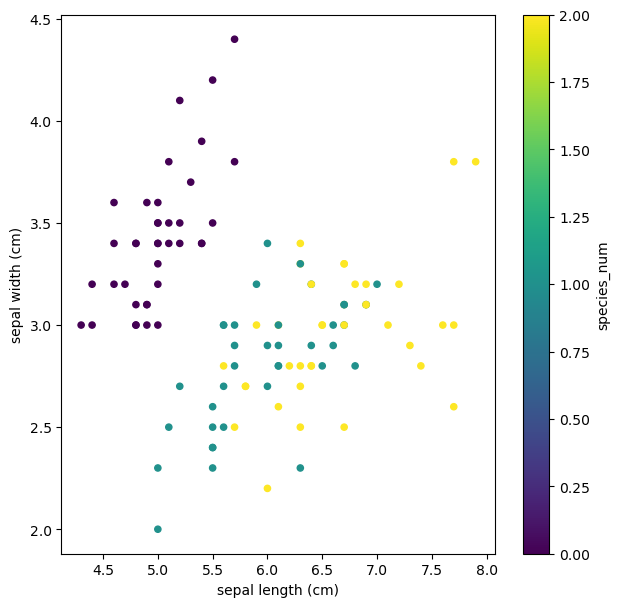

In [44]:
iris_dataframe = pd.DataFrame(X_train, columns = iris_dataset.feature_names)
print(iris_dataframe)
import matplotlib.pyplot as plt
iris_dataframe['species_num'] = y_train
scatter = iris_dataframe.plot(x = 'sepal length (cm)' , y = 'sepal width (cm)', c = 'species_num', cmap = 'viridis', kind = 'scatter', figsize =(7,7))
# violet - setosa, green - versicolour, yellow - virginica


array([[<Axes: xlabel='sepal length (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='sepal width (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='petal length (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='petal width (cm)', ylabel='sepal length (cm)'>,
        <Axes: xlabel='species_num', ylabel='sepal length (cm)'>],
       [<Axes: xlabel='sepal length (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='sepal width (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='petal length (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='petal width (cm)', ylabel='sepal width (cm)'>,
        <Axes: xlabel='species_num', ylabel='sepal width (cm)'>],
       [<Axes: xlabel='sepal length (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='sepal width (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='petal length (cm)', ylabel='petal length (cm)'>,
        <Axes: xlabel='petal width (cm)', ylabel='petal length (cm)'>,
        <Axes

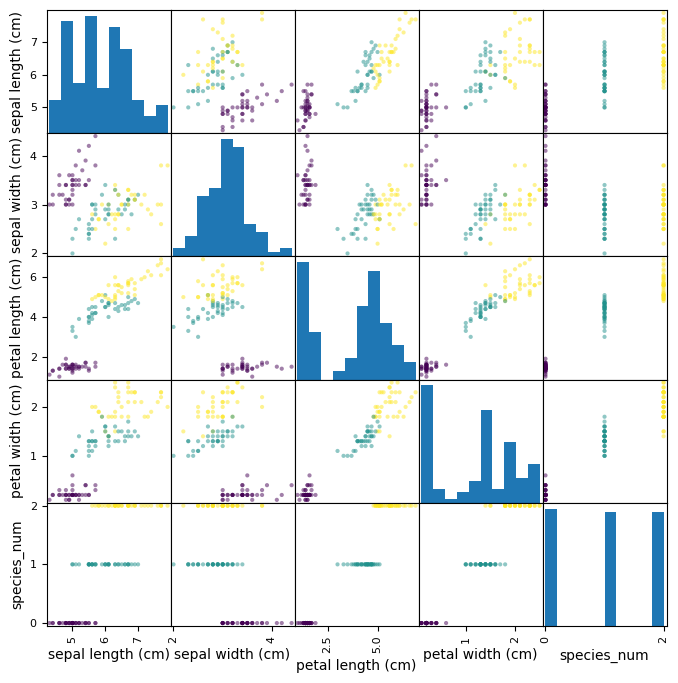

In [45]:
from pandas.plotting import scatter_matrix
scatter_matrix(
    iris_dataframe,
    figsize = (8,8),
    c = iris_dataframe['species_num'],
    diagonal = 'hist'
)
    

Observations:
The range of petal length, petal width, sepal length, sepal width can be found out for each species.
Bottom 4 scatter plots show clear seperation between the 3 species


KNN Algorithm

In [47]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 1)
knn.fit(X_train, y_train)

X_new = ([[4.7, 2.2, 1.5, 1.9]])
prediction = knn.predict(X_new)
print("Prediction: {}".format(prediction))
print("Species: {}".format(iris_dataset['target_names'][prediction]))

Prediction: [1]
Species: ['versicolor']


Checking the accuracy of the model

In [48]:
y_pred = knn.predict(X_test)
y_pred

array([0, 0, 1, 0, 0, 0, 0, 2, 2, 2, 1, 1, 1, 2, 1, 1, 2, 2, 2, 1, 1, 2,
       1, 0, 2, 0, 2, 0, 2, 2, 1, 0, 0, 1, 1, 1, 2, 0])

In [50]:
print("Test set score: {}".format(knn.score(X_test, y_test)))

Test set score: 0.9473684210526315
